RELAÇÃO ENTRE dB E RAZÃO DE AMPLITUDE
    G_dB     |H| = 10^(G/20)      |H|^2 (potência)
--------------------------------------------------------------
       6             1.99526              3.981072
       3             1.41254              1.995262
       0             1.00000              1.000000
      -3             0.70795              0.501187
      -6             0.50119              0.251189
     -20             0.10000              0.010000
     -40             0.01000              0.000100
     -60             0.00100              0.000001

|H| = 1/sqrt(2) = 0.70711  ->  -3.0103 dB

PONTOS DA CURVA DO FILTRO (Butterworth ordem 4, wc = 0.2π)
  G_dB         |H|     w (rad/amostra)       w/π
----------------------------------------------------------------------
     0     1.00000             0.00000    0.0000
    -3     0.70795             0.62797    0.1999
   -20     0.10000             1.04678    0.3332
   -40     0.01000             1.59790    0.5086

VERIFICAÇÃO: AMPLITU

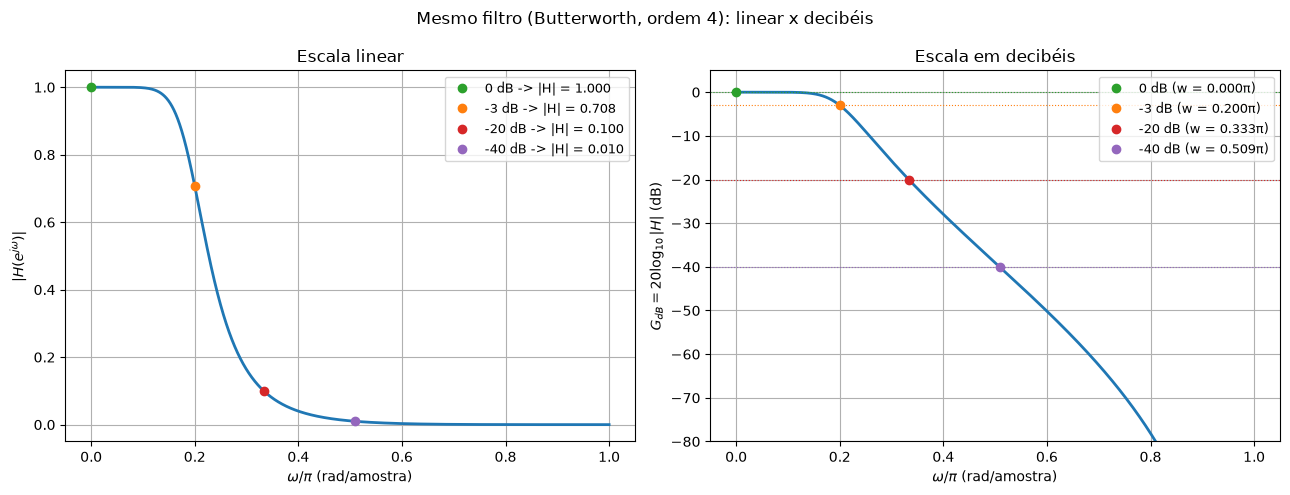

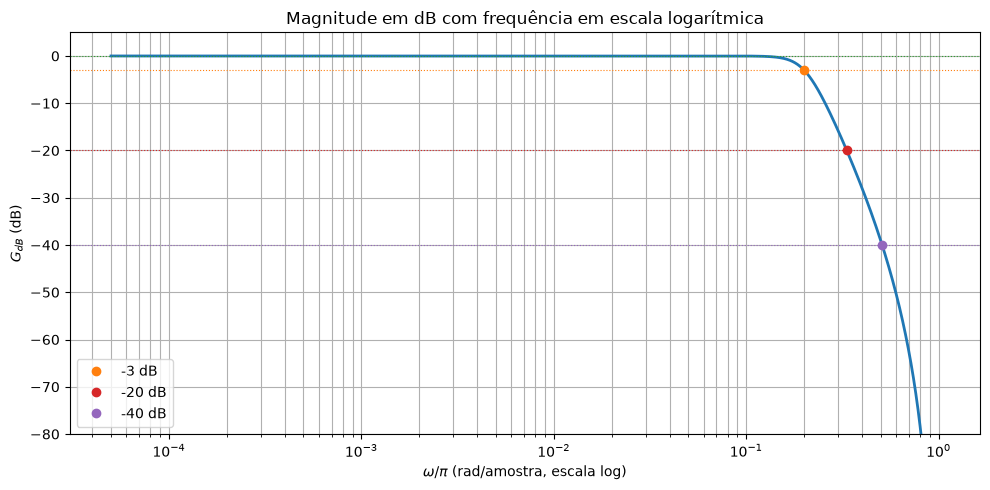

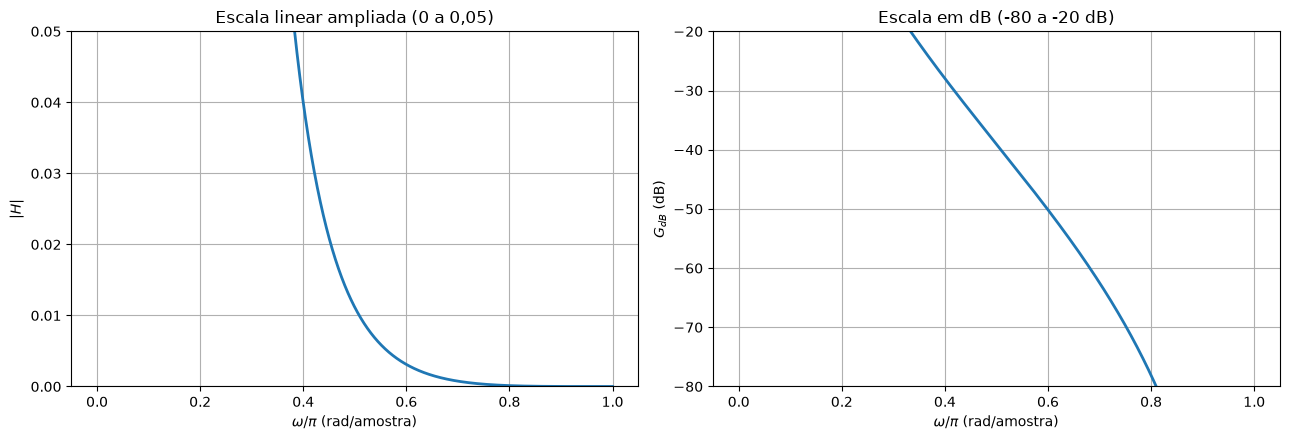

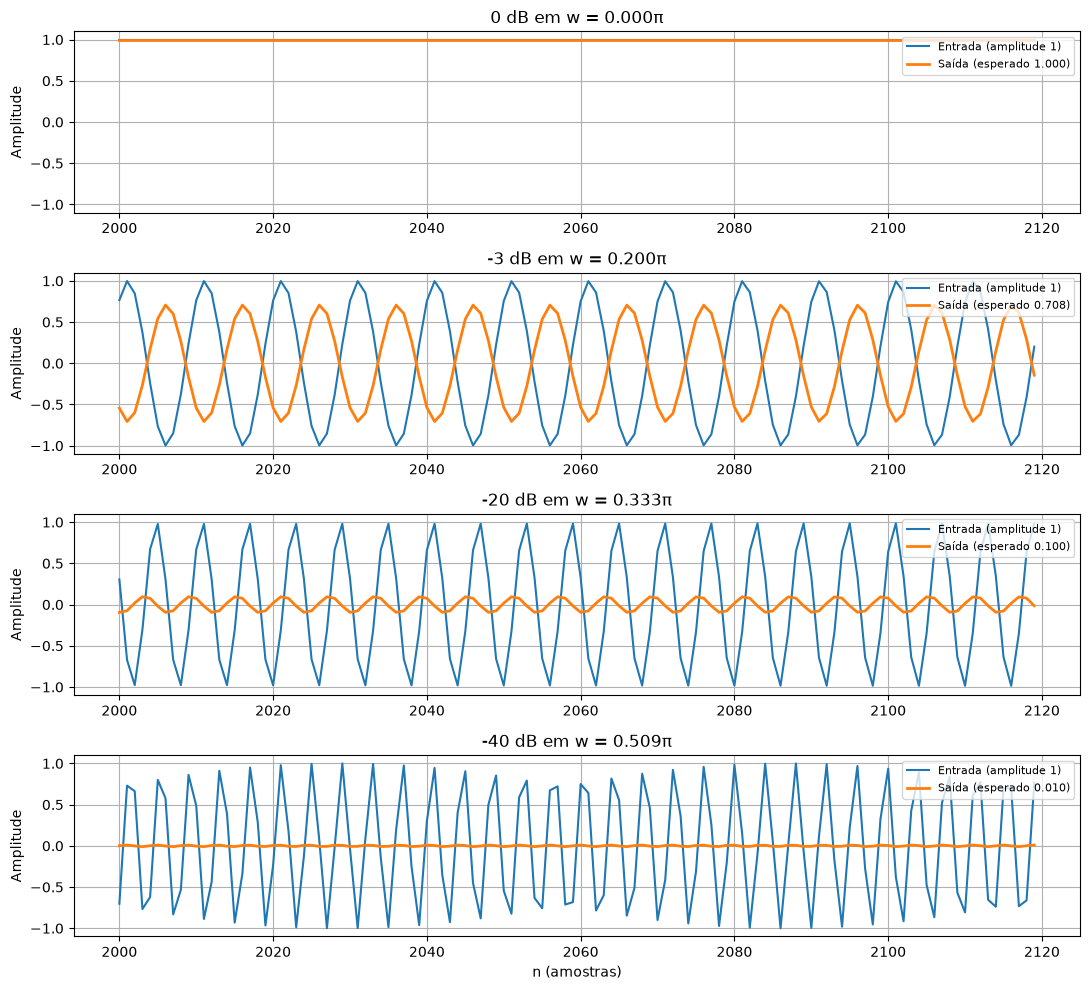


Simulação concluída!


In [1]:
"""
Roteiro de Filtros Digitais - Tópico 3: Magnitude em Decibéis

G_dB(w) = 20 log10 |H(e^{jw})|

Filtro utilizado: passa-baixas Butterworth de ordem 4, frequência de corte
wc = 0,2π rad/amostra (-3 dB). Um filtro com banda passante plana e rejeição
profunda permite observar numa só curva os valores 0, -3, -20 e -40 dB.

A simulação:
    1. representa |H| em escala linear;
    2. representa |H| em decibéis;
    3. localiza as frequências em que G_dB = 0, -3, -20 e -40 dB;
    4. relaciona cada valor em dB à razão de amplitude e confirma, filtrando
       senoides nessas frequências, que a amplitude de saída/entrada é a
       razão prevista.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ============================================================
# 1. FILTRO E RESPOSTA EM FREQUÊNCIA
# ============================================================

ordem = 4
wc_norm = 0.2                       # w/π (Nyquist = 1 em scipy)
b, a = signal.butter(ordem, wc_norm)

w = np.linspace(0, np.pi, 20001)
_, H = signal.freqz(b, a, worN=w)
mag = np.abs(H)
mag_db = 20 * np.log10(np.maximum(mag, 1e-12))

# ============================================================
# 2. RELAÇÃO dB <-> RAZÃO DE AMPLITUDE
# ============================================================

valores_db = [0, -3, -20, -40]


def db_para_razao(g_db):
    return 10 ** (g_db / 20)


def razao_para_db(r):
    return 20 * np.log10(r)


print("RELAÇÃO ENTRE dB E RAZÃO DE AMPLITUDE")
print("=" * 62)
print(f"{'G_dB':>8}{'|H| = 10^(G/20)':>20}{'|H|^2 (potência)':>22}")
print("-" * 62)
for g in [6, 3, 0, -3, -6, -20, -40, -60]:
    r = db_para_razao(g)
    print(f"{g:>8}{r:>20.5f}{r ** 2:>22.6f}")
print(f"\n|H| = 1/sqrt(2) = {1 / np.sqrt(2):.5f}  ->  "
      f"{razao_para_db(1 / np.sqrt(2)):.4f} dB")

# ============================================================
# 3. FREQUÊNCIAS ONDE O FILTRO ATINGE CADA NÍVEL
# ============================================================
# |H| é monotonicamente decrescente (Butterworth): primeiro cruzamento.

pontos = {}
for g in valores_db:
    if g == 0:
        pontos[g] = 0.0
    else:
        i = np.argmax(mag_db <= g)
        # interpolação linear entre amostras vizinhas
        w_i = np.interp(g, [mag_db[i], mag_db[i - 1]], [w[i], w[i - 1]])
        pontos[g] = w_i

print("\nPONTOS DA CURVA DO FILTRO (Butterworth ordem "
      f"{ordem}, wc = {wc_norm}π)")
print("=" * 70)
print(f"{'G_dB':>6}{'|H|':>12}{'w (rad/amostra)':>20}{'w/π':>10}")
print("-" * 70)
for g, wg in pontos.items():
    Hg = np.abs(signal.freqz(b, a, worN=[wg])[1][0])
    print(f"{g:>6}{Hg:>12.5f}{wg:>20.5f}{wg / np.pi:>10.4f}")

# ============================================================
# 4. VERIFICAÇÃO NO TEMPO: GANHO MEDIDO x GANHO PREVISTO
# ============================================================


def amplitude_estacionaria(y, w0, n0):
    """Amplitude da componente em w0 em y[n0:], por mínimos quadrados."""
    n = np.arange(len(y))[n0:]
    A = np.column_stack([np.cos(w0 * n), np.sin(w0 * n)])
    c, *_ = np.linalg.lstsq(A, y[n0:], rcond=None)
    return np.hypot(*c)


N = 4000
n = np.arange(N)
print("\nVERIFICAÇÃO: AMPLITUDE DE SAÍDA / AMPLITUDE DE ENTRADA")
print("=" * 70)
print(f"{'G_dB':>6}{'w/π':>10}{'razão prevista':>18}"
      f"{'razão medida':>16}{'dB medido':>12}")
print("-" * 70)
saidas = {}
for g, wg in pontos.items():
    x = np.cos(wg * n)
    y = signal.lfilter(b, a, x)
    saidas[g] = (x, y)
    r_med = amplitude_estacionaria(y, wg, N // 2)
    print(f"{g:>6}{wg / np.pi:>10.4f}{db_para_razao(g):>18.5f}"
          f"{r_med:>16.5f}{razao_para_db(r_med):>12.3f}")

# ============================================================
# FIGURAS
# ============================================================

cores = {0: "tab:green", -3: "tab:orange", -20: "tab:red", -40: "tab:purple"}

# Fig. 1: linear x dB lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

eixos[0].plot(w / np.pi, mag, linewidth=2)
for g, wg in pontos.items():
    eixos[0].plot(wg / np.pi, db_para_razao(g), "o", color=cores[g],
                  label=f"{g} dB -> |H| = {db_para_razao(g):.3f}")
eixos[0].set_title("Escala linear")
eixos[0].set_ylabel(r"$|H(e^{j\omega})|$")

eixos[1].plot(w / np.pi, mag_db, linewidth=2)
for g, wg in pontos.items():
    eixos[1].plot(wg / np.pi, g, "o", color=cores[g],
                  label=f"{g} dB (w = {wg / np.pi:.3f}π)")
    eixos[1].axhline(g, color=cores[g], linestyle=":", linewidth=0.8)
eixos[1].set_title("Escala em decibéis")
eixos[1].set_ylabel(r"$G_{dB} = 20\log_{10}|H|$ (dB)")
eixos[1].set_ylim(-80, 5)

for ax in eixos:
    ax.set_xlabel(r"$\omega/\pi$ (rad/amostra)")
    ax.grid(True)
    ax.legend(loc="upper right", fontsize=9)
plt.suptitle("Mesmo filtro (Butterworth, ordem 4): linear x decibéis")
plt.tight_layout()
plt.show()

# Fig. 2: mesma curva com eixo de frequência em escala logarítmica
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogx(w[1:] / np.pi, mag_db[1:], linewidth=2)
for g, wg in pontos.items():
    if g != 0:
        ax.plot(wg / np.pi, g, "o", color=cores[g], label=f"{g} dB")
    ax.axhline(g, color=cores[g], linestyle=":", linewidth=0.8)
ax.set_xlabel(r"$\omega/\pi$ (rad/amostra, escala log)")
ax.set_ylabel(r"$G_{dB}$ (dB)")
ax.set_title("Magnitude em dB com frequência em escala logarítmica")
ax.set_ylim(-80, 5)
ax.grid(True, which="both")
ax.legend()
plt.tight_layout()
plt.show()

# Fig. 3: efeito da escala sobre a rejeição (detalhe em baixa amplitude)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
eixos[0].plot(w / np.pi, mag, linewidth=2)
eixos[0].set_ylim(0, 0.05)
eixos[0].set_title("Escala linear ampliada (0 a 0,05)")
eixos[0].set_ylabel(r"$|H|$")
eixos[1].plot(w / np.pi, mag_db, linewidth=2)
eixos[1].set_ylim(-80, -20)
eixos[1].set_title("Escala em dB (-80 a -20 dB)")
eixos[1].set_ylabel(r"$G_{dB}$ (dB)")
for ax in eixos:
    ax.set_xlabel(r"$\omega/\pi$ (rad/amostra)")
    ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 4: senoides filtradas nas frequências de 0, -3, -20 e -40 dB
fig, eixos = plt.subplots(4, 1, figsize=(11, 10), sharey=True)
trecho = slice(N // 2, N // 2 + 120)
for ax, (g, (x, y)) in zip(eixos, saidas.items()):
    ax.plot(n[trecho], x[trecho], label="Entrada (amplitude 1)")
    ax.plot(n[trecho], y[trecho], label=f"Saída (esperado {db_para_razao(g):.3f})",
            linewidth=2)
    ax.set_title(f"{g} dB em w = {pontos[g] / np.pi:.3f}π")
    ax.set_ylabel("Amplitude")
    ax.grid(True)
    ax.legend(loc="upper right", fontsize=8)
eixos[-1].set_xlabel("n (amostras)")
plt.tight_layout()
plt.show()

print("\nSimulação concluída!")